In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

def calc_hist_nonuniform(vals, bins, weights, density=False):
    if weights is None:
        weights = np.ones(vals.shape)    
    hist, bins = np.histogram(vals, bins=bins, weights=weights)    
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    for i in range(1, len(bins)):
        hist[i-1] /= (bins[i] - bins[i-1])
        errs[i-1] /= (bins[i] - bins[i-1])
    if density:
        hist /= weights.sum()
        errs /= weights.sum()
    return hist, errs, bins

def get_data(observables, filename, treename):
    return uproot.open(filename)[treename].arrays(observables, library='pd')

In [3]:
def calc_hist(vals, bins=10, weights=None, density=False):    
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
    return hist, errs, bins

In [4]:
EMB_FILE   = '/gpfs01/star/pwg/youqi/run12/final_0628/results_20235003/matched/all050124_rc_notrueptcons.root'
DATA_FILE  = '/gpfs01/star/pwg/youqi/run12/ppRun12_analysis_code/Results/data/data0613_chargedrc.root'

COLUMNS    = ['pt', 'b', 'w', 'y1', 'y2', 'phi1', 'phi2',
              'pts', 'bs', 'ws', 'y1s', 'y2s', 'phi1s', 'phi2s', 'nefs']

PT_EDGES   = [15, 20, 25, 30, 40, 60]
PT_CENTERS = [17.5, 22.5, 27.5, 35, 50]
PT_XERR    = [2.5, 2.5, 2.5, 5, 10]
B_BINS     = np.array([-1.2, 0.0, 1.2])

In [5]:
df_allreco = get_data(COLUMNS, EMB_FILE, 'MatchedTree').query('pts>15 and bs!=-9 and w<1').copy()
tree_data = uproot.open(DATA_FILE)['ResultTree'].arrays(['pt', 'b'], library='np')
df_data = pd.DataFrame({
    'pts': np.concatenate(tree_data['pt']),
    'bs':  np.concatenate(tree_data['b']),
}).query('pts>15 and bs!=-9 and bs!=0')

# Reweight to match the pT spectrum in data

jet spectrum ratio (data/emb): [0.98773829 1.03816619 1.0772542  1.06624948 1.14991864]


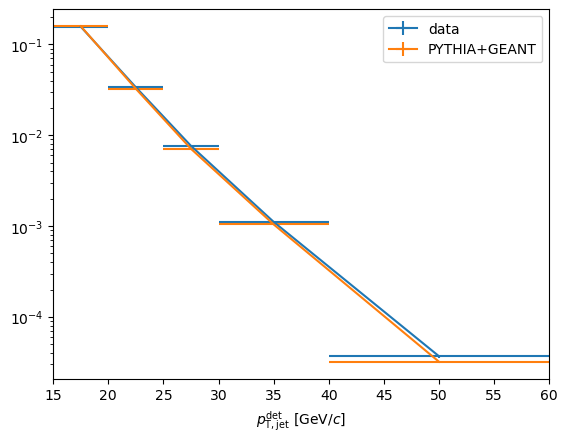

In [6]:
y_data, err_data = calc_hist_nonuniform(df_data['pts'], bins=PT_EDGES, weights=np.ones(df_data.shape[0]), density=True)[:2]
y_prior, err_prior = calc_hist_nonuniform(df_allreco['pts'], bins=PT_EDGES, weights=df_allreco['w'], density=True)[:2]
plt.errorbar(PT_CENTERS, y_data, xerr=PT_XERR,  yerr=err_data, label='data')
plt.errorbar(PT_CENTERS, y_prior, xerr=PT_XERR, yerr=err_prior, label='PYTHIA+GEANT')
print('jet spectrum ratio (data/emb):', y_data/y_prior)
plt.xlabel('$p_{\mathrm{T,jet}}^{\mathrm{det}}$ [GeV$/c$]')
plt.xlim(PT_EDGES[0], PT_EDGES[-1])
plt.yscale('log')
plt.legend()
plt.show()

In [7]:
y_ratio = y_data/y_prior
rw = pd.cut(df_allreco['pts'], bins=PT_EDGES, labels=y_ratio).astype(float).fillna(1.0).values
df_allreco['w'] *= rw
df_allreco['ws'] *= rw

Process PYTHIA6+GEANT

In [8]:
def delta_phi(a, b):
    diff = np.abs(a - b)
    return np.minimum(diff, 2 * np.pi - diff)
    
df_allreco['distance1'] = np.sqrt(
    delta_phi(df_allreco['phi1'].values, df_allreco['phi1s'].values)**2
    + (df_allreco['y1'].values - df_allreco['y1s'].values)**2)
df_allreco['distance2'] = np.sqrt(
    delta_phi(df_allreco['phi2'].values, df_allreco['phi2s'].values)**2
    + (df_allreco['y2'].values - df_allreco['y2s'].values)**2)
df_match   = df_allreco.query('pt!=-9 and b!=-9 and distance1<0.02 and distance2<0.02')
df_allfake = df_allreco.query('pt==-9 or b==-9 or distance1>0.02 or distance2>0.02')

In [10]:
print(df_match.shape[0], df_allfake.shape[0])

2630097 1465062


In [11]:
print(np.unique(df_match['bs']))

[-1  1]


In [9]:
df_allreco_pts_array = [ df_allreco[(df_allreco.pts>15) & (df_allreco.pts<20)],\
                       df_allreco[(df_allreco.pts>20) & (df_allreco.pts<25)],\
                       df_allreco[(df_allreco.pts>25) & (df_allreco.pts<30)],\
                       df_allreco[(df_allreco.pts>30) & (df_allreco.pts<40)],\
                       df_allreco[(df_allreco.pts>40) & (df_allreco.pts<60)]]

df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)],\
                       df_match[(df_match.pts>40) & (df_match.pts<60)] ]

df_allfake_pts_array = [ df_allfake[(df_allfake.pts>15) & (df_allfake.pts<20)],\
                       df_allfake[(df_allfake.pts>20) & (df_allfake.pts<25)],\
                       df_allfake[(df_allfake.pts>25) & (df_allfake.pts<30)],\
                       df_allfake[(df_allfake.pts>30) & (df_allfake.pts<40)],\
                       df_allfake[(df_allfake.pts>40) & (df_allfake.pts<60)]  ]

In [10]:
rc_allreco_bs_vs_pts_array = []
rc_err_allreco_bs_vs_pts_array = []
for i in range(0, len(df_allreco_pts_array)):
    rc_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[0])
    rc_err_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[1])
    
rc_match_bs_vs_pts_array = []
rc_err_match_bs_vs_pts_array = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[1])

rc_allfake_bs_vs_pts_array = []
rc_err_allfake_bs_vs_pts_array = []
for i in range(0, len(df_allfake_pts_array)):
    rc_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[0])
    rc_err_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[1])

In [17]:
plt.rcParams['font.size'] = 12

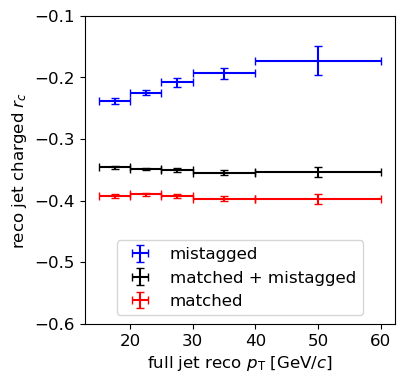

In [18]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_allfake_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_allfake_bs_vs_pts_array, capsize=3, color='b', ls='none', label='mistagged')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_allreco_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_allreco_bs_vs_pts_array, capsize=3, color='k', ls='none', label='matched + mistagged')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array, capsize=3, color='r', ls='none', label='matched')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('reco jet charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')

In [14]:
rc_allfake_bs_vs_pts_array

[-0.2381034581515094,
 -0.22484574982877806,
 -0.2081112905981685,
 -0.19305953641181442,
 -0.1727017686454619]

In [11]:
ob = 'b'
range_low = -1.2
range_high = 1.2
bins = 2

In [12]:
b_fake_array = []
for i in range(0,5):
    df_fake_pts = df_allfake_pts_array[i]
    y_fake_rec,yerr_fake_rec,x = calc_hist_nonuniform(df_fake_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_pts['ws'], density=True)
    b_fake_array.append(y_fake_rec/sum(y_fake_rec))

In [17]:
b_fake_array

[array([0.61905173, 0.38094827]),
 array([0.61242287, 0.38757713]),
 array([0.60405565, 0.39594435]),
 array([0.59652977, 0.40347023]),
 array([0.58635088, 0.41364912])]

In [13]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)],\
                       df_match[(df_match.pt>40) & (df_match.pt<60)]  ]

In [14]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[1])

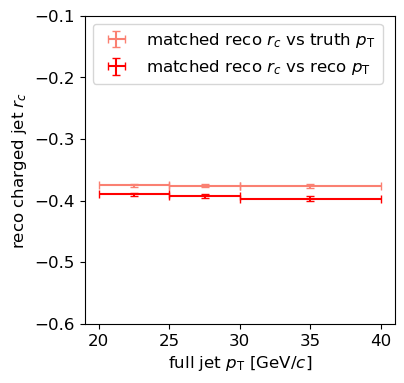

In [26]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:-1], capsize=3, color='salmon', ls='none', label='matched reco $r_c$ vs truth $p_{\mathrm{T}}$')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:-1], capsize=3, color='r', ls='none', label='matched reco $r_c$ vs reco $p_{\mathrm{T}}$')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV$/c$]')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='upper left')

In [26]:
b_match_array = []
for i in range(0,5):
    df_match_pts = df_match_pts_array[i]
    y_reco,yerr_reco,x = calc_hist_nonuniform(df_match_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_pts['ws'], density=True)
    b_match_array.append(y_reco/sum(y_reco))
    print(y_reco/sum(y_reco))

[0.69613892 0.30386108]
[0.69480392 0.30519608]
[0.69601395 0.30398605]
[0.69861309 0.30138691]
[0.69865203 0.30134797]


In [15]:
binedges=[5,10,15,20,25,30,40,60]
match_fake, x = np.histogram(df_allreco['pts'], bins=binedges, weights=df_allreco['ws'])
match, _ = np.histogram(df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['pts'], bins=binedges, weights=df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['ws'])
eff4 = match/match_fake

/tmp/ipykernel_904329/4101531506.py:4: RuntimeWarning: invalid value encountered in divide
  eff4 = match/match_fake


In [23]:
fake_rate_array = np.ones(5)-eff4[2:7]
fake_rate_array

array([0.29936725, 0.24871326, 0.22291703, 0.2064793 , 0.19306711])

Process data

In [16]:
df_data_pts_array = [ df_data[(df_data.pts>15) & (df_data.pts<20)],\
                       df_data[(df_data.pts>20) & (df_data.pts<25)],\
                       df_data[(df_data.pts>25) & (df_data.pts<30)],\
                       df_data[(df_data.pts>30) & (df_data.pts<40)],\
                       df_data[(df_data.pts>40) & (df_data.pts<60)]  ]

In [17]:
def getRcAndErrAndN(df, ob):
    if (ob == 'bs'):
        nos = df[df.bs==-1].shape[0]
        nss = df[df.bs==+1].shape[0]
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    n = nss+nos
    rc_err = 2*np.sqrt(p*(1-p)/n)
    return rc, rc_err, n

In [18]:
rc_data_bs_vs_pts_array = []
rc_err_data_bs_vs_pts_array = []
for i in range(0, len(df_data_pts_array)):
    rc_data_bs_vs_pts_array.append(getRcAndErrAndN(df_data_pts_array[i], 'bs')[0])
    rc_err_data_bs_vs_pts_array.append(getRcAndErrAndN(df_data_pts_array[i], 'bs')[1])

In [19]:
b_data_array = []
for i in range(0,5):
    df_data_pts = df_data_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df_data_pts['bs'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins))
    b_data_array.append(y_reco)

In [20]:
print(b_data_array)

[array([337314., 178144.]), array([72379., 38554.]), array([16450.,  8688.]), array([4758., 2573.]), array([334., 153.])]


# 1. Mistagged subtraction

In [21]:
def getMatchedCountAndErr(data, fake_rate, fake_dist):
    corrected = data - sum(data) * fake_rate * fake_dist
    err = np.sqrt(corrected)
    return corrected, err

In [24]:
b_fakesubtracted_array = []
b_fakesubtractederr_array = []
rc1_array = []
rc1_err_array = []
for i in range(0,5):
    print(i)
    print(b_data_array[i])
    #print(getRc(data_array[i]))
    b_fakesubtracted, b_fakesubtractederr = getMatchedCountAndErr(b_data_array[i], fake_rate_array[i], b_fake_array[i])
    b_fakesubtracted_array.append(b_fakesubtracted)
    b_fakesubtractederr_array.append(b_fakesubtractederr)
    print(b_fakesubtracted)
    print(b_fakesubtractederr)
    nos = b_fakesubtracted[0]
    nss = b_fakesubtracted[1]
    n = nos + nss
    p = nss / n
    rc1 = (nss-nos) / (nss+nos)
    rc1_array.append(rc1)
    rc1_err_array.append( 2*np.sqrt(p*(1-p)/n) )

0
[337314. 178144.]
[241787.35901385 119359.39929276]
[491.71878042 345.48429674]
1
[72379. 38554.]
[55481.94187548 27860.55029639]
[235.54605043 166.91479951]
2
[16450.  8688.]
[13065.06044942  6469.25125311]
[114.30249538  80.43165579]
3
[4758. 2573.]
[3855.03301837 1962.26719705]
[62.0889122  44.29748522]
4
[334. 153.]
[278.86912984 114.10718633]
[16.69937513 10.68209653]


In [30]:
print(rc_data_bs_vs_pts_array)

[-0.3087933449476, -0.3049137767841851, -0.30877555891479036, -0.2980493793479744, -0.37166324435318276]


Text(20, -0.2, '$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')

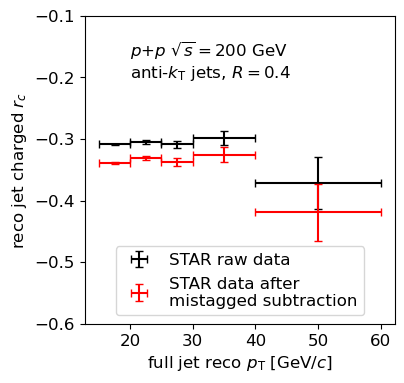

In [55]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_data_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_data_bs_vs_pts_array, capsize=3, color='k', ls='none', label='STAR raw data')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='r', ls='none', label='STAR data after\nmistagged subtraction')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('reco jet charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')
plt.text(20, -0.2, '$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$')

# 2. $p_T$ correction

In [27]:
reweight_array, reweight_err_array = [], []
for i in range(5):
    num     = b_fakesubtracted_array[i] / sum(b_fakesubtracted_array[i])
    denom   = b_match_array[i]          / sum(b_match_array[i])
    rw      = num / denom
    reweight_array.append(rw)

In [32]:
reweight_array

[array([0.96173176, 1.08767168]),
 array([0.95812662, 1.09532818]),
 array([0.960938  , 1.08943732]),
 array([0.94857114, 1.11921181]),
 array([1.01571797, 0.96355909])]

([], [])

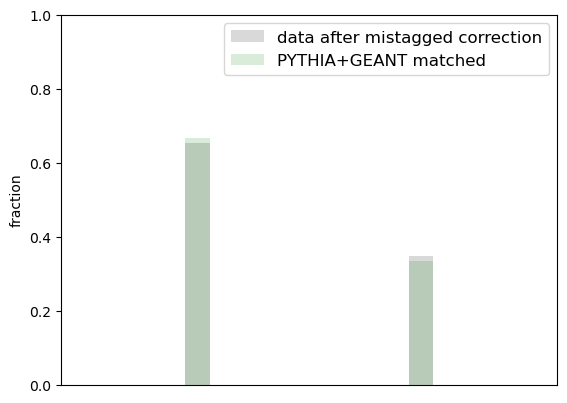

In [33]:
x = np.array([-0.5, 0.5])
plt.hist(x, weights=b_data_array[1]/sum(b_data_array[1]), color='k', alpha=0.15, label='data after mistagged correction')
plt.hist(x, weights=b_fakesubtracted_array[1]/sum(b_fakesubtracted_array[1]), ls='none', color='g', alpha=0.15, label='PYTHIA+GEANT matched')
#plt.errorbar(x+np.array([0.05,-0.05]), b_data_array[1][0]/sum(b_data_array[1]), yerr=y1err_array[0]/sum(b_data_array[1]), capsize=3, color='k', ls='none')
#plt.errorbar(x+np.array([0.05,-0.05]), b_fakesubtracted_array[1][0]/sum(b_fakesubtracted_array[1]), yerr=y1err_pythia_array[0]/sum(b_fakesubtracted_array[1]), capsize=3, color='g', ls='none')
plt.legend(fontsize=12)
plt.ylabel('fraction')
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)
plt.xlim(-1,1)
plt.ylim(0,1)
plt.xlabel('')
plt.xticks([])

Reweight PYTHIA6+GEANT

In [28]:
rw = np.array(reweight_array)   # shape (5, 2): rw[i,0]=os weight, rw[i,1]=ss weight
pts_vals = df_match['pts'].values
bs_vals  = df_match['bs'].values
bin_idx  = np.clip(np.digitize(pts_vals, PT_EDGES) - 1, 0, 4)
df_match = df_match.copy()
df_match['r'] = np.where(bs_vals == -1, rw[bin_idx, 0], rw[bin_idx, 1])

In [29]:
def getRcAndErrNew(df, ob):
    if (ob == 'b'):
        nos = sum(np.array(df[df.b==-1]['w'])* np.array(df[df.b==-1]['r']))
        nss = sum(np.array(df[df.b==+1]['w'])* np.array(df[df.b==1]['r']))
    elif (ob == 'b_ch'):
        nos = sum(np.array(df[df.b_ch==-1]['w'])* np.array(df[df.b_ch==-1]['r']))
        nss = sum(np.array(df[df.b_ch==+1]['w'])* np.array(df[df.b_ch==1]['r']))
    elif (ob == 'bs'):
        nos = sum(np.array(df[df.bs==-1]['ws'])* np.array(df[df.bs==-1]['r']))
        nss = sum(np.array(df[df.bs==+1]['ws'])* np.array(df[df.bs==1]['r']))
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    #print(w_array)
    err2_array = []
    #variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w']) * np.array(df[df.w == w_array[i]]['r']))
        elif (ob == 'b_ch'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w'] * df[df.w == w_array[i]]['r']))         
        elif (ob == 'bs'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['ws']) * np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w'] * df[df.w == w_array[i]]['r']))
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        #print(variance)
        #variance_array_test.append(variance)
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    #print(variance_array_test)
    rc_err = 2*np.sqrt(sum(err2_array))
    #print(n)
    return rc, rc_err

In [30]:
df_match[df_match['w'].isna()]

,pt,b,w,y1,y2,phi1,phi2,pts,bs,ws,y1s,y2s,phi1s,phi2s,nefs,distance1,distance2,r


In [33]:
print(np.unique(df_match['w']))
print(np.unique(df_match['ws']))

[1.11817290e-15 1.13205382e-15 1.17526000e-15 1.20705179e-15
 1.21950972e-15 1.30176978e-15 2.20882221e-14 2.23624237e-14
 2.32159122e-14 2.38439226e-14 2.40900147e-14 2.57149678e-14
 1.83643279e-13 1.85923014e-13 1.93018987e-13 1.98240317e-13
 2.00286347e-13 2.13796339e-13 3.97343578e-12 4.02276172e-12
 4.17629522e-12 4.28926760e-12 4.33353695e-12 4.62584868e-12
 1.27186440e-11 1.33679805e-11 1.37295959e-11 1.38712985e-11
 1.48069645e-11 2.06067818e-11 2.16588386e-11 2.22447289e-11
 2.24743158e-11 1.31948558e-10 1.38685049e-10 1.43906681e-10
 3.33076279e-10 3.50081126e-10 6.76448661e-09]
[1.11817290e-15 1.13205382e-15 1.17526000e-15 1.20705179e-15
 1.21950972e-15 1.30176978e-15 2.20882221e-14 2.23624237e-14
 2.32159122e-14 2.38439226e-14 2.40900147e-14 2.57149678e-14
 1.83643279e-13 1.85923014e-13 1.93018987e-13 1.98240317e-13
 2.00286347e-13 2.13796339e-13 3.97343578e-12 4.02276172e-12
 4.17629522e-12 4.28926760e-12 4.33353695e-12 4.62584868e-12
 1.27186440e-11 1.33679805e-11 1.37295

In [31]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)],\
                       df_match[(df_match.pt>40) & (df_match.pt<60)] ]
df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)],\
                       df_match[(df_match.pts>40) & (df_match.pts<60)]  ]

In [34]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    # print(i)
    # print(df_match_pt_array[i])
    rc_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[1])
rc_match_bs_vs_pts_array_rw = []
rc_err_match_bs_vs_pts_array_rw = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array_rw.append(getRcAndErrNew(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array_rw.append(getRcAndErrNew(df_match_pts_array[i], 'bs')[1])

Check that the reweighted embedding is the same as data

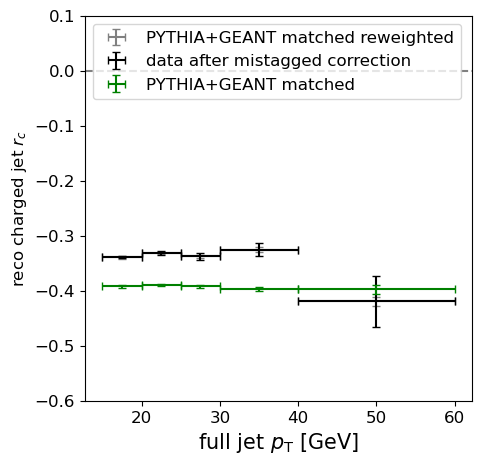

In [67]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array_rw, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array_rw, capsize=3, color='grey', ls='none', label='PYTHIA+GEANT matched reweighted')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='k', ls='none', label='data after mistagged correction')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array, capsize=3, color='g', ls='none', label='PYTHIA+GEANT matched')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

In [63]:
print(rc_match_bs_vs_pts_array_rw)

[-0.3389978087990394, -0.3314202738463346, -0.3376525007257003, -0.3253684271399414, -0.4192668533074789]


Text(20, -0.25, 'STAR data\n$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')

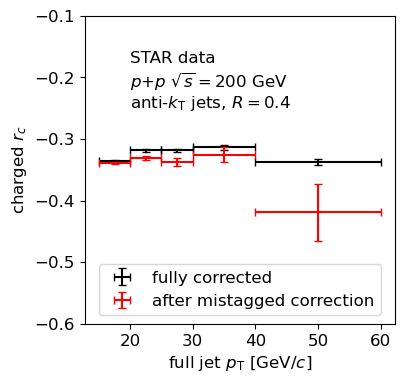

In [64]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pt_array, capsize=3, color='k', ls='none', label='fully corrected')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='r', ls='none', label='after mistagged correction')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')
plt.text(20, -0.25, 'STAR data\n$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$')

Plot result

(-0.6, 0.1)

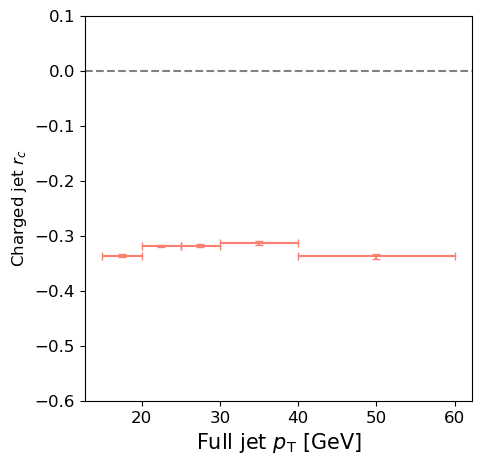

In [65]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pt_array, capsize=3, color='salmon', ls='none', label='sample 1 corrected')
#plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:], capsize=3, color='r', ls='none', label='sample 1 corrected')
plt.xlabel('Full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('Charged jet $r_c$')
plt.ylim(-0.6,0.1)
#plt.legend(loc='upper left', fontsize=15)

In [66]:
rc_match_bs_vs_pt_array

[-0.3363383503313372,
 -0.31858421634077183,
 -0.31837883403935086,
 -0.3137246070368501,
 -0.337476670722872]

In [93]:
rc_err_match_bs_vs_pt_array

[0.002902329760794436,
 0.0022562811409388753,
 0.0027941445346627894,
 0.003496919848053088,
 0.005194905950704135]